In [1]:
import os

import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GridSearchCV, cross_val_predict
from sklearn.linear_model import Ridge

In [2]:
path = kagglehub.competition_download('house-prices-advanced-regression-techniques')

print("Path to competition files:", path)

Path to competition files: C:\Users\da1zy\.cache\kagglehub\competitions\house-prices-advanced-regression-techniques


In [3]:
print(os.listdir(path))

['data_description.txt', 'sample_submission.csv', 'test.csv', 'train.csv']


In [4]:
df_train = pd.read_csv('{}/train.csv'.format(path))
df_test = pd.read_csv('{}/test.csv'.format(path))

In [5]:
df_train.shape, df_test.shape

((1460, 81), (1459, 80))

In [6]:
df_train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [7]:
X = df_train.drop(columns=['SalePrice', 'Id'])
y = df_train['SalePrice']

In [8]:
num_features = X.select_dtypes(include=['number']).columns
cat_features = X.select_dtypes(include=['str', 'category']).columns

In [9]:
numerical_pipeline = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler()
)
categorical_pipeline = make_pipeline(
    SimpleImputer(strategy='constant', fill_value='Missing'),
    OneHotEncoder(handle_unknown='ignore')
)

In [10]:
preprocess = ColumnTransformer([
    ('numerical', numerical_pipeline, num_features),
    ('categorical', categorical_pipeline, cat_features)
])

In [11]:
model = make_pipeline(preprocess, Ridge())

In [12]:
params = {
    'ridge__alpha': list(range(5, 30, 1))
}
gs = GridSearchCV(estimator=model,
                  param_grid=params,
                  cv=10,
                  scoring='neg_root_mean_squared_error')
gs.fit(X, np.log1p(y))
print(-gs.best_score_)
print(gs.best_params_)

0.13628961813870158
{'ridge__alpha': 19}


In [13]:
y_pred_log = cross_val_predict(
    gs.best_estimator_,
    X,
    np.log1p(y),
    cv=10
)
y_pred = np.expm1(y_pred_log)

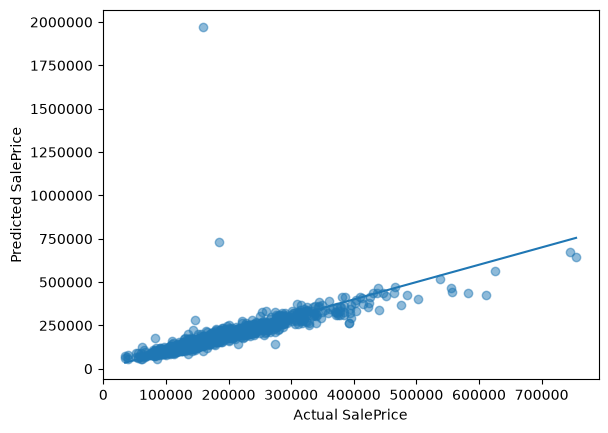

In [14]:
fig, ax = plt.subplots()
ax.scatter(y, y_pred, alpha=0.5)
ax.plot([y.min(), y.max()], [y.min(), y.max()])
ax.ticklabel_format(style='plain')
ax.set_xlabel('Actual SalePrice')
ax.set_ylabel('Predicted SalePrice')
plt.show()